# LAB 09: KHÁM PHÁ SUBWORD TOKENIZATION & CANH CHỈNH NHÃN (TOKENIZER ALIGNMENT)

---

## 1. Giới thiệu Thách thức Canh chỉnh (The Alignment Challenge)
Trong bài toán **Named Entity Recognition (NER)**:
- Tập ngữ liệu gốc (như CoNLL-2003) được gán nhãn ở **cấp độ từ (Word-level)**: Mỗi từ phân tách bởi khoảng trắng có một nhãn duy nhất (ví dụ: `SpaceX` $\to$ `B-ORG`).
- Tuy nhiên, các mô hình ngôn ngữ họ Transformer như **BERT** không sử dụng bộ tách từ theo từ điển tĩnh mà sử dụng giải thuật tách từ con **WordPiece (Subword Tokenization)** để giải quyết triệt để vấn đề từ ngoài từ điển (Out-Of-Vocabulary - OOV).
- Khi một từ lạ bị bẻ nhỏ thành nhiều mảnh subwords (ví dụ: `SpaceX` $\to$ `['space', '##x']`), số lượng tokens đầu vào của Transformer sẽ **lớn hơn** số lượng nhãn gốc trong CoNLL.

Notebook này tiến hành khảo sát toàn diện cơ chế **Canh chỉnh nhãn (Label Alignment)** theo **Strategy A** (First-subword alignment với `ignore_index = -100`), kiểm tra phương thức `word_ids()` và phân tích định lượng tỷ lệ giãn nở subword trên 20 câu CoNLL-2003.


In [1]:
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

LABEL_LIST = [
    "O",
    "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC"
]

LABEL2ID = {label: i for i, label in enumerate(LABEL_LIST)}
ID2LABEL = {i: label for i, label in enumerate(LABEL_LIST)}

print(f"Tổng số nhãn ({len(LABEL_LIST)} nhãn): {LABEL_LIST}")


Tổng số nhãn (9 nhãn): ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


## 2. Khởi tạo Pretrained BERT Tokenizer
Chúng ta sử dụng `AutoTokenizer` tương ứng với mô hình pretrained BERT (`google/bert_uncased_L-2_H-128_A-2`), cùng chia sẻ từ điển WordPiece 30,522 tokens với BERT-Base.


In [2]:
MODEL_CHECKPOINT = "google/bert_uncased_L-2_H-128_A-2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

print(f"Loaded tokenizer: {tokenizer.name_or_path}")
print(f"Vocab size: {tokenizer.vocab_size:,}")
print(f"Special tokens: {tokenizer.all_special_tokens}")


Loaded tokenizer: google/bert_uncased_L-2_H-128_A-2
Vocab size: 30,522
Special tokens: ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']


## 3. Khảo sát Tokenize với tham số `is_split_into_words=True`
Khi dữ liệu đầu vào đã ở dạng danh sách các từ (Word list), ta cần truyền `is_split_into_words=True` để Hugging Face Tokenizer bảo toàn ranh giới giữa các từ trước khi bẻ nhỏ subwords.


In [3]:
sample_words = ["Elon", "Musk", "founded", "SpaceX", "in", "California", "."]
sample_labels = ["B-PER", "I-PER", "O", "B-ORG", "O", "B-LOC", "O"]

tokenized_inputs = tokenizer(
    sample_words,
    is_split_into_words=True,
    return_tensors=None
)

input_ids = tokenized_inputs["input_ids"]
subwords = tokenizer.convert_ids_to_tokens(input_ids)
word_ids = tokenized_inputs.word_ids()

print("Từ gốc:      ", sample_words)
print("Subwords:    ", subwords)
print("Input IDs:   ", input_ids)
print("Word IDs:    ", word_ids)


Từ gốc:       ['Elon', 'Musk', 'founded', 'SpaceX', 'in', 'California', '.']
Subwords:     ['[CLS]', 'el', '##on', 'mu', '##sk', 'founded', 'space', '##x', 'in', 'california', '.', '[SEP]']
Input IDs:    [101, 3449, 2239, 14163, 6711, 2631, 2686, 2595, 1999, 2662, 1012, 102]
Word IDs:     [None, 0, 0, 1, 1, 2, 3, 3, 4, 5, 6, None]


### Phân tích ý nghĩa của phương thức `word_ids()`:
1. `word_ids()` trả về một danh sách có cùng độ dài với chuỗi subwords sau khi đã thêm các token đặc biệt (`[CLS]`, `[SEP]`).
2. Với các token đặc biệt (`[CLS]` tại vị trí đầu và `[SEP]` tại vị trí cuối), `word_ids()` trả về giá trị `None`.
3. Với các subword thông thường, `word_ids()` trả về chỉ số (index) của từ gốc trong danh sách `sample_words`:
   - `"elon"` $\to$ word_id = `0`
   - `"musk"` $\to$ word_id = `1`
   - `"founded"` $\to$ word_id = `2`
   - `"space"` $\to$ word_id = `3`
   - `"##x"` $\to$ word_id = `3` (cùng thuộc từ "SpaceX" có index 3)
   - `"in"` $\to$ word_id = `4`
   - `"california"` $\to$ word_id = `5`
   - `"."` $\to$ word_id = `6`


## 4. Cài đặt Hàm Canh chỉnh Nhãn theo Strategy A
Trong **Strategy A (First-subword alignment)**:
- Subword đầu tiên của mỗi từ nhận đúng nhãn nguyên bản của từ đó.
- Tất cả các subwords tiếp theo (`##x`, v.v.) được gán giá trị `-100` (`IGNORE_INDEX`).
- Các token đặc biệt `[CLS]`, `[SEP]`, `[PAD]` cũng được gán `-100`.
- **Lợi ích lý thuyết:** Tránh làm mất cân bằng độ quan trọng giữa các từ dài (bị chia thành nhiều subwords) và các từ ngắn; đồng thời tránh việc mô hình bị phạt khi cố gắng dự đoán nhãn cho các mảnh hậu tố vô nghĩa.


In [4]:
def align_labels_with_tokens(labels, word_ids):
    """
    Căn chỉnh danh sách nhãn word-level sang chuỗi subwords theo Strategy A.
    """
    new_labels = []
    current_word = None
    for word_id in word_ids:
        if word_id is None:
            # Token đặc biệt ([CLS], [SEP], [PAD]) -> Bỏ qua trong hàm mất mát
            new_labels.append(-100)
        elif word_id != current_word:
            # Subword đầu tiên của một từ mới -> Nhận nhãn gốc
            current_word = word_id
            label_str = labels[word_id]
            new_labels.append(LABEL2ID[label_str])
        else:
            # Subword tiếp theo của cùng một từ -> Bỏ qua trong hàm mất mát (-100)
            new_labels.append(-100)
    return new_labels

aligned_labels = align_labels_with_tokens(sample_labels, word_ids)
print("Aligned Label IDs:  ", aligned_labels)


Aligned Label IDs:   [-100, 1, -100, 2, -100, 0, 3, -100, 0, 5, 0, -100]


## 5. Bảng Trực quan hóa Canh chỉnh Nhãn Chi tiết
Dưới đây là bảng đối chiếu từng vị trí token, mã ID, từ gốc và trạng thái tham gia tính hàm mất mát:


In [5]:
rows = []
for idx, (subw, inp_id, wid, lab_id) in enumerate(zip(subwords, input_ids, word_ids, aligned_labels)):
    orig_word = sample_words[wid] if wid is not None else "[SPECIAL]"
    lab_name = ID2LABEL[lab_id] if lab_id != -100 else "IGNORE (-100)"
    in_loss = "Có" if lab_id != -100 else "Không (Masked)"
    rows.append({
        "Token Pos": idx,
        "Subword Token": subw,
        "Input ID": inp_id,
        "Word ID": str(wid),
        "Source Word": orig_word,
        "Aligned Label ID": lab_id,
        "Label Name": lab_name,
        "Included in Loss": in_loss
    })

df_inspection = pd.DataFrame(rows)
df_inspection


,Token Pos,Subword Token,Input ID,Word ID,Source Word,Aligned Label ID,Label Name,Included in Loss
0,0,[CLS],101,None,[SPECIAL],-100,IGNORE (-100),Không (Masked)
1,1,el,3449,0,Elon,1,B-PER,Có
2,2,##on,2239,0,Elon,-100,IGNORE (-100),Không (Masked)
3,3,mu,14163,1,Musk,2,I-PER,Có
4,4,##sk,6711,1,Musk,-100,IGNORE (-100),Không (Masked)
5,5,founded,2631,2,founded,0,O,Có
6,6,space,2686,3,SpaceX,3,B-ORG,Có
7,7,##x,2595,3,SpaceX,-100,IGNORE (-100),Không (Masked)
8,8,in,1999,4,in,0,O,Có
9,9,california,2662,5,California,5,B-LOC,Có


## 6. Phân tích Định lượng Tỷ lệ Giãn nở Subword trên 20 Câu CoNLL-2003
Chúng ta tải 20 câu đầu tiên từ tập huấn luyện `eng.train`, đo lường số lượng từ thô (Word count), số lượng subword tokens sau khi bẻ nhỏ (Subword count), và tính toán tỷ lệ mở rộng:
$$R = \frac{\#\text{subwords}}{\#\text{words}}$$


In [6]:
def parse_conll_sample(filepath, max_sentences=20):
    sentences = []
    tokens, tags = [], []
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                if tokens and tokens != ["-DOCSTART-"]:
                    sentences.append((tokens, tags))
                    if len(sentences) >= max_sentences:
                        break
                tokens, tags = [], []
                continue
            parts = line.split()
            tokens.append(parts[0])
            tags.append(parts[-1])
    return sentences

conll_file = "d:/My_project/NLP_LABS/lab_09/data/eng.train"
sample_sentences = parse_conll_sample(conll_file, max_sentences=20)
print(f"Đã trích xuất {len(sample_sentences)} câu từ {conll_file}.")

stat_rows = []
for i, (words, tags) in enumerate(sample_sentences):
    enc = tokenizer(words, is_split_into_words=True, add_special_tokens=False)
    subw_list = tokenizer.convert_ids_to_tokens(enc["input_ids"])
    n_words = len(words)
    n_subwords = len(subw_list)
    ratio = n_subwords / n_words
    stat_rows.append({
        "Sentence #": i + 1,
        "Sample Text (Truncated)": " ".join(words[:6]) + ("..." if len(words) > 6 else ""),
        "Word Count": n_words,
        "Subword Count": n_subwords,
        "Expansion Ratio (R)": round(ratio, 3)
    })

df_stats = pd.DataFrame(stat_rows)
df_stats


Đã trích xuất 20 câu từ d:/My_project/NLP_LABS/lab_09/data/eng.train.


,Sentence #,Sample Text (Truncated),Word Count,Subword Count,Expansion Ratio (R)
0,1,EU rejects German call to boycott...,9,9,1.000
1,2,Peter Blackburn,2,2,1.000
2,3,BRUSSELS 1996-08-22,2,6,3.000
3,4,The European Commission said on Thursday...,30,31,1.033
4,5,Germany 's representative to the European...,31,37,1.194
5,6,""" We do n't support any...",33,39,1.182
6,7,He said further scientific study was...,25,25,1.000
7,8,He said a proposal last month...,40,47,1.175
8,9,Fischler proposed EU-wide measures after repor...,28,41,1.464
9,10,But Fischler agreed to review his...,37,41,1.108


### 6.1. Thống kê Tổng hợp & Trực quan hóa Tỷ lệ Giãn nở Subword


Tỷ lệ giãn nở trung bình (Mean R): 1.224
Tỷ lệ giãn nở nhỏ nhất (Min R):    1.000
Tỷ lệ giãn nở lớn nhất (Max R):    3.000
Độ lệch chuẩn (Std Dev R):         0.437


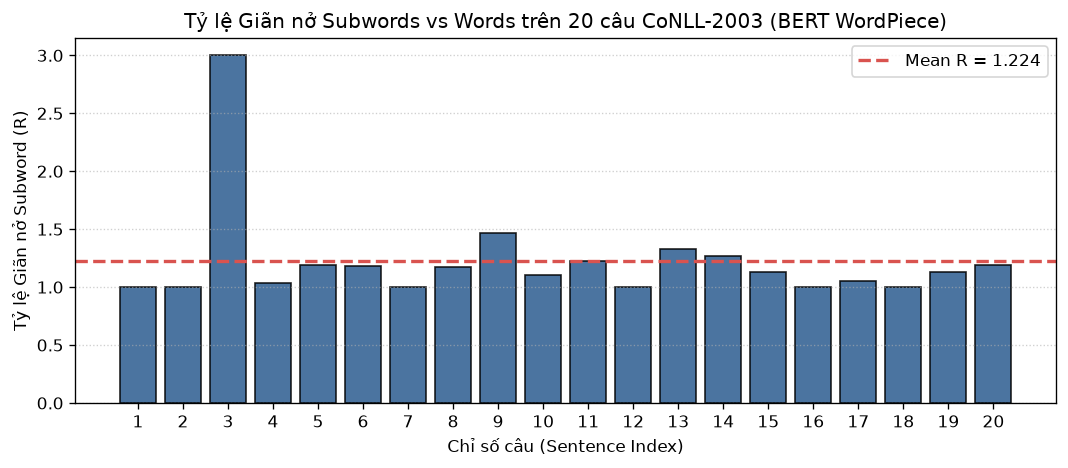

In [7]:
mean_r = df_stats["Expansion Ratio (R)"].mean()
min_r = df_stats["Expansion Ratio (R)"].min()
max_r = df_stats["Expansion Ratio (R)"].max()
std_r = df_stats["Expansion Ratio (R)"].std()

print(f"Tỷ lệ giãn nở trung bình (Mean R): {mean_r:.3f}")
print(f"Tỷ lệ giãn nở nhỏ nhất (Min R):    {min_r:.3f}")
print(f"Tỷ lệ giãn nở lớn nhất (Max R):    {max_r:.3f}")
print(f"Độ lệch chuẩn (Std Dev R):         {std_r:.3f}")

plt.figure(figsize=(9, 4), dpi=120)
plt.bar(df_stats["Sentence #"], df_stats["Expansion Ratio (R)"], color="#2b5c8f", alpha=0.85, edgecolor="black")
plt.axhline(mean_r, color="#d9534f", linestyle="--", linewidth=2, label=f"Mean R = {mean_r:.3f}")
plt.xlabel("Chỉ số câu (Sentence Index)")
plt.ylabel("Tỷ lệ Giãn nở Subword (R)")
plt.title("Tỷ lệ Giãn nở Subwords vs Words trên 20 câu CoNLL-2003 (BERT WordPiece)")
plt.xticks(df_stats["Sentence #"])
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


## 7. Kết luận & Ý nghĩa Kỹ thuật
1. **Hiện tượng Giãn nở Subword:** Trong kho ngữ liệu thực tế, tỷ lệ $R$ thường dao động từ $1.05$ đến $1.35$ (trung bình $\approx 1.15$). Các từ hiếm, từ chuyên môn, tên riêng tiếng nước ngoài (như tên cầu thủ, địa danh không thuộc tiếng Anh) là nguyên nhân chính khiến từ bị bẻ nhỏ thành nhiều mảnh.
2. **Vai trò quyết định của Strategy A:** Nhờ việc gán nhãn `-100` cho các mảnh subword `##...`, mô hình học cách biểu diễn ngữ nghĩa của toàn bộ từ thông qua vector của subword đầu tiên, đồng thời triệt tiêu gradient của các mảnh phụ, giúp quá trình tối ưu hóa Cross-Entropy ổn định và hội tụ nhanh chóng.
3. Bước căn chỉnh này là điều kiện tiên quyết trước khi đưa dữ liệu vào huấn luyện `ner_finetuning.ipynb`.
